# Test the training stack

An invoice shows an amount due that differs from the sum of its lines and tax. Does the model copy
the printed value? Test whether a preference stage helps reward training preserve it.

Use one supervised anchor and a matched two-by-two comparison. Choose the reward learning rate on
separate development families and reuse the same rollout budget in both scored GRPO arms.

Select **T4 GPU** in Colab and run all cells in order. Allow 45–65 minutes as a planning estimate.
The one-update preflight runs before the full fits. Read its memory and time measurements first.

[Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/06-test-the-training-stack)

## 0. Environment

Install the pinned training libraries and retain Colab's CUDA PyTorch build. The receipt records
the trainer package, PyTorch and CUDA versions.

In [1]:
import subprocess
import sys

TRAINER_PINS = {'transformers': '4.51.3', 'peft': '0.15.2', 'trl': '0.19.1', 'accelerate': '1.6.0', 'datasets': '3.6.0'}
pins = [f"{name}=={version}" for name, version in TRAINER_PINS.items()]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pins], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.51.3', 'peft==0.15.2', 'trl==0.19.1', 'accelerate==1.6.0', 'datasets==3.6.0'], returncode=0)

## 1. Invoice catalog

The synthetic catalog supplies split labels and expected records for scoring. The model prompt
contains the extraction contract and visible invoice text.

In [2]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

In [3]:
"""Notebook-local Qwen text training and matched invoice evaluation."""

import gc
import hashlib
import json
import math
import random
import time
from collections import defaultdict
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainerCallback, set_seed
from trl import SFTConfig, SFTTrainer

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REV = "7ae557604adf67be50417f59c2c2f167def9a775"
SEED = 42
DEVICE = "cuda"
DTYPE = torch.float16
PROMPT_LIMIT = 512
ANSWER_LIMIT = 256
OUT = Path("lesson-results")

SYSTEM = VISIBLE_CONTRACT

def dialogs(invoice, system=SYSTEM):
    return [{"role": "system", "content": system}, {"role": "user", "content": invoice_text(invoice)}]


def packed(record):
    return json.dumps(record, ensure_ascii=False, separators=(",", ":"))


def supervised_row(invoice, answer=None, system=SYSTEM):
    return {
        "prompt": dialogs(invoice, system=system),
        "completion": [{"role": "assistant", "content": packed(invoice_record(invoice)) if answer is None else answer}],
    }


def prepare_kernel():
    pins = globals().get("TRAINER_PINS", {})
    installed = {name: version(name) for name in pins}
    if installed != pins:
        raise RuntimeError(f"Restart the kernel and install the pinned training packages: {installed}")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a T4 GPU in Colab before running all cells.")
    name = torch.cuda.get_device_name(0)
    if "T4" not in name:
        raise RuntimeError(f"Expected a Colab T4 for comparable timings; found {name}.")
    OUT.mkdir(exist_ok=True)
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV, trust_remote_code=False)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    print(name, "|", torch.__version__, "| revision", MODEL_REV[:12])
    print("Trainer packages", installed, "| CUDA", torch.version.cuda)
    return tok


def manifest(invoices):
    rows = sorted(
        (invoice.key, invoice.family, invoice.split, invoice_text(invoice), invoice_record(invoice))
        for invoice in invoices
    )
    return hashlib.sha256(packed(rows).encode()).hexdigest()


def model_at(source=MODEL_ID):
    options = {"revision": MODEL_REV} if source == MODEL_ID else {}
    model = AutoModelForCausalLM.from_pretrained(
        source, **options, torch_dtype=DTYPE, device_map={"": DEVICE},
        trust_remote_code=False, attn_implementation="sdpa", use_safetensors=True,
    )
    if source == MODEL_ID and model.config._commit_hash != MODEL_REV:
        raise RuntimeError("Loaded weights do not match the pinned revision.")
    return model


def clean_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


def lora():
    return LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.0,
        target_modules=["q_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM",
    )


def prompt_tokens(row, tok):
    return tok.apply_chat_template(row["prompt"], tokenize=True, add_generation_prompt=True)


def token_budget(rows, tok, labelled=None):
    max_prompt = max(len(prompt_tokens(item, tok)) for item in rows)
    if labelled is None:
        labelled = [encode_supervised(item, tok) for item in rows if "completion" in item]
    max_answer = max((sum(row["completion_mask"]) for row in labelled), default=0)
    if max_prompt > PROMPT_LIMIT or max_answer > ANSWER_LIMIT:
        raise ValueError(f"Token limits would clip this dataset: prompt={max_prompt}, answer={max_answer}.")
    return {"max_prompt_tokens": max_prompt, "max_label_tokens": max_answer}


def encode_supervised(row, tok):
    prompt = prompt_tokens(row, tok)
    full = tok.apply_chat_template(row["prompt"] + row["completion"], tokenize=True)
    if full[:len(prompt)] != prompt:
        raise ValueError("The tokenized chat prefix changed when the answer was appended.")
    completion = full[len(prompt):]
    ids = prompt + completion[:completion.index(tok.eos_token_id) + 1]
    return {"input_ids": ids, "completion_mask": [0] * len(prompt) + [1] * (len(ids) - len(prompt))}


def check_sft_labels(trainer, encoded):
    for start in range(0, len(encoded), trainer.args.per_device_train_batch_size):
        examples = encoded[start:start + trainer.args.per_device_train_batch_size]
        batch = trainer.data_collator(examples)
        for labels, example in zip(batch["labels"].tolist(), examples, strict=True):
            expected = [token if keep else -100 for token, keep in
                        zip(example["input_ids"], example["completion_mask"], strict=True)]
            if labels != expected + [-100] * (len(labels) - len(expected)):
                raise AssertionError("SFT loss includes prompt or padding, or dropped a response token.")
    return sum(sum(row["completion_mask"]) for row in encoded)


class OptimizerAudit(TrainerCallback):
    def __init__(self):
        self.completed = 0
        self.skipped = 0

    def on_optimizer_step(self, args, state, control, optimizer, **kwargs):
        if optimizer.step_was_skipped:
            self.skipped += 1
        else:
            self.completed += 1


def capture_fit(trainer):
    audit = OptimizerAudit()
    trainer.add_callback(audit)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    trainer.train()
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    if (trainer.state.global_step, audit.completed, audit.skipped) != (trainer.args.max_steps, trainer.args.max_steps, 0):
        raise RuntimeError(f"Optimizer budget mismatch: completed={audit.completed}, skipped={audit.skipped}.")
    return {
        "steps": trainer.state.global_step,
        "optimizer_updates": audit.completed,
        "seconds": time.perf_counter() - started,
        "peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else None,
        "peak_reserved_gib": torch.cuda.max_memory_reserved() / 2**30 if DEVICE == "cuda" else None,
        "log": [
            {key: None if isinstance(value, float) and not math.isfinite(value) else value
             for key, value in row.items()}
            for row in trainer.state.log_history
        ],
    }


def fit_sft(rows, tok, name, *, steps=32, source=MODEL_ID, lr=2e-4):
    encoded = [encode_supervised(row, tok) for row in rows]
    lengths = token_budget(rows, tok, encoded)
    set_seed(SEED)
    base = model_at(source)
    base.config.use_cache = False
    args = SFTConfig(
        output_dir=str(OUT / f"{name}-trainer"),
        max_steps=steps, max_length=PROMPT_LIMIT + ANSWER_LIMIT,
        per_device_train_batch_size=4, gradient_accumulation_steps=2,
        learning_rate=lr, lr_scheduler_type="constant", completion_only_loss=True,
        fp16=True, bf16=False, gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=4, save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
    )
    trainer = SFTTrainer(
        model=base, args=args, train_dataset=Dataset.from_list(encoded),
        processing_class=tok, peft_config=lora(),
    )
    label_tokens = check_sft_labels(trainer, encoded)
    stats = {**capture_fit(trainer), **lengths, "examples": len(rows), "learning_rate": lr,
             "roster_supervised_tokens": label_tokens, "examples_per_update": 8}
    checkpoint = str(OUT / name)
    trainer.model.save_pretrained(checkpoint)
    del trainer, base
    clean_memory()
    print(name, {key: value for key, value in stats.items() if key != "log"})
    return checkpoint, stats


def merge_adapter(source, adapter, name):
    base = model_at(source)
    loaded = PeftModel.from_pretrained(base, adapter)
    merged = loaded.merge_and_unload()
    merged.config.use_cache = True
    target = str(OUT / name)
    merged.save_pretrained(target, safe_serialization=True)
    del merged, loaded, base
    clean_memory()
    return target


def checkpoint_digest(path):
    digest = hashlib.sha256()
    directory = Path(path)
    files = sorted(item for item in directory.iterdir() if item.suffix in {".json", ".safetensors"})
    if not any(item.suffix == ".safetensors" for item in files):
        raise ValueError(f"No saved weights in {directory}.")
    for item in files:
        digest.update(item.name.encode())
        with item.open("rb") as stream:
            digest.update(hashlib.file_digest(stream, "sha256").digest())
    return digest.hexdigest()


def trainable_digest(model):
    digest = hashlib.sha256()
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            digest.update(name.encode())
            digest.update(parameter.detach().float().cpu().numpy().tobytes())
    return digest.hexdigest()


def fixed_eval(catalog, per_slice=None, splits=("familiar", "novel", "independent")):
    rng = random.Random(SEED)
    picked = []
    for split in splits:
        rows = [invoice for invoice in catalog if invoice.split == split]
        if not rows:
            raise ValueError(f"No data for fixed slice {split}")
        if per_slice is not None and len(rows) > per_slice:
            rows = rng.sample(rows, per_slice)
        picked.extend(rows)
    assert len({row.key for row in picked}) == len(picked)
    return picked


def eos_ids(model, tok):
    value = model.generation_config.eos_token_id
    ids = value if isinstance(value, list) else [value]
    return {token for token in [tok.eos_token_id, *ids] if token is not None}


@torch.inference_mode()
def evaluate(model, tok, invoices, *, system=SYSTEM, answer_limit=ANSWER_LIMIT, extract=lambda text: text):
    model.eval()
    model.config.use_cache = True
    output = []
    eos = eos_ids(model, tok)
    for i in range(0, len(invoices), 8):
        part = invoices[i:i + 8]
        rendered = [tok.apply_chat_template(dialogs(invoice, system), tokenize=False, add_generation_prompt=True)
                    for invoice in part]
        batch = tok(rendered, add_special_tokens=False, return_tensors="pt", padding=True).to(DEVICE)
        if batch.input_ids.shape[1] > PROMPT_LIMIT:
            raise ValueError("An evaluation prompt exceeded the declared token budget.")
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        tokens = model.generate(**batch, max_new_tokens=answer_limit, do_sample=False,
                                pad_token_id=tok.pad_token_id)[:, batch.input_ids.shape[1]:]
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        latency = (time.perf_counter() - started) * 1000 / len(part)
        texts = tok.batch_decode(tokens, skip_special_tokens=True)
        for invoice, token_row, text in zip(part, tokens.tolist(), texts, strict=True):
            boundary = next((index for index, token in enumerate(token_row) if token in eos), None)
            record = score_record(extract(text), invoice)
            output.append({
                "key": invoice.key, "family": invoice.family, "split": invoice.split,
                "valid": float(record["valid"]), "exact": float(record["exact"]),
                "fields": record["fields"], "row_f1": float(record["row_f1"]),
                "natural_completion": boundary is not None,
                "generated_tokens": len(token_row) if boundary is None else boundary + 1,
                "ms_per_example_in_batch": latency,
                "completion": text,
            })
    return output


def evaluate_at(source, tok, invoices, *, adapter=None, **kwargs):
    base = model_at(source)
    model = PeftModel.from_pretrained(base, adapter) if adapter else base
    scores = evaluate(model, tok, invoices, **kwargs)
    del model, base
    clean_memory()
    return scores


def summary(scores):
    mean = lambda key: sum(row[key] for row in scores) / len(scores)
    return {
        "n": len(scores), "exact": mean("exact"), "valid": mean("valid"),
        "row_f1": mean("row_f1"), "natural_completion": mean("natural_completion"),
        "mean_generated_tokens": mean("generated_tokens"),
        "mean_ms_per_example_in_batch": mean("ms_per_example_in_batch"),
    }


def paired_change(before, after, *, score="exact", seed=SEED):
    left = {row["key"]: row for row in before}
    right = {row["key"]: row for row in after}
    assert set(left) == set(right) and len(left) == len(before) == len(after)
    by_family = defaultdict(list)
    for key, row in sorted(left.items()):
        by_family[row["family"]].append(right[key][score] - row[score])
    changes = [value for values in by_family.values() for value in values]
    groups = list(by_family.values())
    rng = random.Random(seed)
    boot = []
    if len(groups) >= 2:
        for _ in range(2000):
            sampled = [value for group in rng.choices(groups, k=len(groups)) for value in group]
            boot.append(sum(sampled) / len(sampled))
    return {
        "delta": sum(changes) / len(changes), "n": len(changes), "families": len(groups),
        "improved": sum(change > 0 for change in changes),
        "regressed": sum(change < 0 for change in changes),
        "tied": sum(change == 0 for change in changes),
        "paired_family_bootstrap_95": np.quantile(boot, [0.025, 0.975]).tolist() if boot else None,
    }


def stage_interaction(scores):
    lookup = [{row["key"]: row["exact"] for row in run} for run in scores]
    keys = sorted(lookup[0])
    assert all(set(run) == set(keys) for run in lookup)
    rows = []
    for baseline in scores[0]:
        key = baseline["key"]
        start, dpo, grpo, combined = [run[key] for run in lookup]
        rows.append({"key": key, "family": baseline["family"], "exact": combined - dpo - grpo + start})
    return paired_change(
        [dict(row, exact=0.0) for row in rows], rows,
    )


def write_report(lesson, report, **tables):
    for key, values in tables.items():
        pd.DataFrame(values).to_csv(OUT / f"{lesson}-{key}.csv", index=False)
    full = {
        "model": MODEL_ID, "revision": MODEL_REV, "seed": SEED,
        "hardware": torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE,
        "packages": {name: version(name) for name in ("torch", "transformers", "peft", "trl", "accelerate", "datasets")},
        "prompt_token_cap": PROMPT_LIMIT, "completion_token_cap": ANSWER_LIMIT,
        **report,
    }
    (OUT / f"{lesson}-report.json").write_text(json.dumps(full, indent=2, allow_nan=False) + "\n")
    print(json.dumps(full, indent=2, allow_nan=False))


def plot_slices(summaries, title, filename="exact.svg"):
    plt.rcParams["svg.fonttype"] = "none"
    from IPython.display import SVG, display
    fig, ax = plt.subplots(figsize=(9, 4))
    keys = list(summaries)
    values = [summaries[label]["exact"] for label in keys]
    ax.barh(keys, values, color=["#74818c", "#2a78d6", "#eb6834", "#426a53", "#746296"][:len(keys)])
    ax.set(xlim=(0, 1.05), xlabel="Exact complete records, share", title=title)
    ax.bar_label(ax.containers[0], labels=[f"{value:.1%}" for value in values], padding=4)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.22)
    fig.tight_layout()
    svg_path = OUT / filename
    fig.savefig(svg_path, format="svg")
    plt.close(fig)
    display(SVG(filename=str(svg_path)))

In [4]:
# SPDX-License-Identifier: Apache-2.0
# Adapted from the Together Post-Training Cookbook revision 226e03ca225d6f13434047cf0f45ab3070a29801.
from collections import Counter
from collections.abc import Callable, Iterable, Sequence
from dataclasses import dataclass, field
from typing import TypeVar
import torch.nn.functional as F
Item = TypeVar('Item')

def oversample_until_kept(
    draw_batch: Callable[[], Iterable[Item]],
    *,
    is_kept: Callable[[Item], bool],
    target: int,
    max_attempts: int,
) -> tuple[list[Item], int]:
    """Keep rejected groups in the audit trail while bounding draws."""
    if target <= 0 or max_attempts <= 0:
        raise ValueError("Target and maximum attempts must be positive.")
    items: list[Item] = []
    kept = 0
    for attempts in range(1, max_attempts + 1):
        for item in draw_batch():
            items.append(item)
            if is_kept(item):
                kept += 1
                if kept >= target:
                    return items, attempts
    return items, max_attempts

In [5]:
"""Reward shaping and condition checks kept independent of the release scorer."""

import json
from collections import Counter


def _unique_reward_keys(pairs):
    if len(dict(pairs)) != len(pairs):
        raise ValueError("duplicate key")
    return dict(pairs)


def reward_components(completion, expected, *, natural_stop):
    """Score structure and field fidelity without calling the held-out scorer."""
    try:
        observed = json.loads(completion, object_pairs_hook=_unique_reward_keys)
    except (ValueError, TypeError, RecursionError):
        return {"format": 0.0, "semantic": 0.0, "fields": 0.0, "rows": 0.0, "natural_stop": float(natural_stop)}
    if not isinstance(observed, dict) or set(observed) != set(expected):
        return {"format": 0.0, "semantic": 0.0, "fields": 0.0, "rows": 0.0, "natural_stop": float(natural_stop)}
    rows = observed["line_items"]
    fmt = float(
        all(value is None or isinstance(value, str) for value in
            (observed[key] for key in ("invoice_id", "issued_on", "supplier", "currency")))
        and all(value is None or type(value) is int for value in
                (observed[key] for key in ("subtotal_minor", "tax_minor", "total_minor")))
        and isinstance(rows, list)
        and all(isinstance(row, dict) and set(row) == {"description", "quantity", "unit_minor"}
                and isinstance(row["description"], str) and type(row["quantity"]) is int
                and type(row["unit_minor"]) is int for row in rows)
    )
    if not fmt:
        return {"format": 0.0, "semantic": 0.0, "fields": 0.0, "rows": 0.0, "natural_stop": float(natural_stop)}
    keys = [key for key in expected if key != "line_items"]
    correct = sum(observed[key] == expected[key] for key in keys) / len(keys)
    make_row_counts = lambda records: Counter((r["description"], r["quantity"], r["unit_minor"]) for r in records)
    truth = make_row_counts(expected["line_items"])
    predicted = make_row_counts(rows)
    matches = (truth & predicted).total()
    row_score = 2.0 * matches / max(truth.total() + predicted.total(), 1)
    combined = 0.45 * correct + 0.45 * row_score + 0.1 * float(natural_stop)
    return {"format": fmt, "semantic": combined, "fields": correct, "rows": row_score, "natural_stop": float(natural_stop)}


def replay_cases(invoice):
    """Wrong but well-formed answers expose the range of each reward."""
    record = invoice_record(invoice)
    items = record["line_items"]
    assert len(items) >= 2
    correct = packed(record)
    mutations = [
        ("correct", correct, True),
        ("missing row", packed({**record, "line_items": items[1:]}), True),
        ("duplicate row", packed({**record, "line_items": items + items[:1]}), True),
        ("wrong currency", packed({**record, "currency": "USD" if record["currency"] != "USD" else "EUR"}), True),
        ("reordered rows", packed({**record, "line_items": items[::-1]}), True),
        ("missing EOS", correct, False),
        ("truncated JSON", correct[:-6], False),
    ]
    return [
        {"case": name, "completion": text, **reward_components(text, record, natural_stop=natural),
         "release_exact": score_record(text, invoice)["exact"]}
        for name, text, natural in mutations
    ]


def reward_group_diagnostics(batches):
    """Estimate skip rates on bounded replay, without changing scored GRPO rollouts."""
    stream = iter(batches)
    observed, attempts = oversample_until_kept(
        lambda: next(stream, ()), is_kept=lambda rewards: len(set(rewards)) > 1,
        target=2, max_attempts=3,
    )
    return {
        "attempts": attempts, "groups": len(observed),
        "zero_variance_groups": sum(len(set(group)) < 2 for group in observed),
    }

In [6]:
"""Bounded Transformers GRPO on one T4."""

from trl import GRPOConfig, GRPOTrainer

GROUP_SIZE = 4
GRPO_STEPS = 10
GRPO_BETA = 0.04


def reward_factory(kind, eos_token_id, audit):
    def reward(prompts, completions, completion_ids, gold, record_key, **kwargs):
        pairs = []
        for option, tokens, expected in zip(completions, completion_ids, gold, strict=True):
            if not 0 < len(tokens) <= ANSWER_LIMIT or eos_token_id in tokens[:-1]:
                raise ValueError("GRPO completion IDs crossed the declared cap or EOS boundary.")
            text = option[0]["content"]
            pairs.append(reward_components(text, json.loads(expected),
                                           natural_stop=tokens[-1] == eos_token_id))
        rewards = [item[kind] for item in pairs]
        groups = [rewards[i:i + GROUP_SIZE] for i in range(0, len(rewards), GROUP_SIZE)]
        if (len(groups) != 1 or len(groups[0]) != GROUP_SIZE or len(record_key) != GROUP_SIZE
                or len(set(record_key)) != 1 or len(set(gold)) != 1):
            raise ValueError("Expected one group of four completions for a single invoice.")
        audit.append({
            "rollout_group": len(audit) + 1,
            "rollout_invoice_ids": record_key[::GROUP_SIZE],
            "completions": len(rewards),
            "format_mean": float(np.mean([item["format"] for item in pairs])),
            "semantic_mean": float(np.mean([item["semantic"] for item in pairs])),
            "field_mean": float(np.mean([item["fields"] for item in pairs])),
            "row_f1_mean": float(np.mean([item["rows"] for item in pairs])),
            "completion_rate": float(np.mean([item["natural_stop"] for item in pairs])),
            "mean_tokens": float(np.mean([len(tokens) for tokens in completion_ids])),
            "max_tokens": max(map(len, completion_ids)),
            "cap_hits_without_eos": sum(len(tokens) == ANSWER_LIMIT and tokens[-1] != eos_token_id
                                        for tokens in completion_ids),
            "zero_variance_group_share": float(np.mean([len(set(group)) == 1 for group in groups])),
        })
        return rewards
    reward.__name__ = f"{kind}_reward"
    return reward


def grpo_rows(invoices):
    return [{"prompt": dialogs(inv), "gold": packed(invoice_record(inv)), "record_key": inv.key} for inv in invoices]


def fit_grpo(source, tok, rows, name, *, kind="semantic", steps=GRPO_STEPS, lr=2e-5, beta=0.0,
             save_adapter=True):
    if len(rows) < steps:
        raise ValueError("Set aside at least one distinct training prompt per planned update.")
    lengths = token_budget(rows, tok)
    set_seed(SEED)
    base = model_at(source)
    audit = []
    args = GRPOConfig(
        output_dir=str(OUT / f"{name}-trainer"), max_steps=steps,
        per_device_train_batch_size=GROUP_SIZE, gradient_accumulation_steps=1,
        num_generations=GROUP_SIZE, steps_per_generation=1, max_prompt_length=PROMPT_LIMIT,
        max_completion_length=ANSWER_LIMIT, temperature=0.8, beta=beta,
        num_iterations=1, loss_type="bnpo", scale_rewards=True,
        learning_rate=lr, lr_scheduler_type="constant",
        use_vllm=False, fp16=True, bf16=False, logging_steps=1,
        save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
        remove_unused_columns=False,
    )
    trainer = GRPOTrainer(
        model=base, args=args, reward_funcs=reward_factory(kind, tok.eos_token_id, audit),
        train_dataset=Dataset.from_list(rows), processing_class=tok, peft_config=lora(),
    )
    try:
        initial_digest = trainable_digest(trainer.model)
        stats = {
            **capture_fit(trainer), **lengths, "reward_kind": kind, "learning_rate": lr, "beta": beta,
            "initial_adapter_sha256": initial_digest,
            "prompt_roster_sha256": hashlib.sha256(packed(rows).encode()).hexdigest(),
            "prompt_ids_sha256": hashlib.sha256(packed([r["record_key"] for r in rows]).encode()).hexdigest(),
            "generation_group_size": GROUP_SIZE, "audit": audit,
            "rollout_invoice_ids": [key for batch in audit for key in batch["rollout_invoice_ids"]],
            "completions_sampled": sum(batch["completions"] for batch in audit),
            "generation_settings": trainer.generation_config.to_diff_dict(),
        }
        if (len(audit) != steps or stats["completions_sampled"] != steps * GROUP_SIZE
                or len(set(stats["rollout_invoice_ids"])) != steps):
            raise RuntimeError("Observed rollout groups differ from the fixed training budget.")
        checkpoint = str(OUT / name) if save_adapter else None
        if checkpoint:
            trainer.model.save_pretrained(checkpoint)
            stats["adapter_sha256"] = checkpoint_digest(checkpoint)
    finally:
        del trainer, base
        clean_memory()
    print(name, {key: value for key, value in stats.items() if key not in {"log", "audit"}})
    return checkpoint, stats


def check_profile(receipt):
    return (
        receipt["steps"] == 1 and receipt["completions_sampled"] == GROUP_SIZE
        and receipt["seconds"] <= 45 and receipt["peak_allocated_gib"] <= 10
        and receipt["peak_reserved_gib"] <= min(12, receipt["free_before_gib"] - 2)
        and receipt["allocated_after_gib"] <= receipt["allocated_before_gib"] + 0.125
    )


def profile_grpo(tok, rows):
    clean_memory()
    torch.cuda.synchronize()
    free_before, total = torch.cuda.mem_get_info()
    allocated_before = torch.cuda.memory_allocated()
    if free_before < 12 * 2**30:
        raise RuntimeError("L04 needs at least 12 GiB free before running the one-step T4 profile.")
    longest = max(rows, key=lambda row: len(prompt_tokens(row, tok)))
    try:
        _, stats = fit_grpo(MODEL_ID, tok, [longest], "04-profile", steps=1, beta=GRPO_BETA, save_adapter=False)
    finally:
        clean_memory()
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
        set_seed(SEED)
    receipt = {
        **{name: stats[name] for name in ("steps", "completions_sampled", "seconds", "peak_allocated_gib",
                                         "peak_reserved_gib", "max_prompt_tokens")},
        "max_completion_tokens_observed": stats["audit"][0]["max_tokens"],
        "free_before_gib": free_before / 2**30, "total_gib": total / 2**30,
        "allocated_before_gib": allocated_before / 2**30,
        "allocated_after_gib": torch.cuda.memory_allocated() / 2**30,
    }
    receipt["passed"] = check_profile(receipt)
    (OUT / "04-t4-profile.json").write_text(json.dumps(receipt, indent=2) + "\n")
    print("One-step T4 profile", receipt)
    if not receipt["passed"]:
        raise RuntimeError("L04 T4 profile exceeded its time, memory or cleanup guard. Stop before the full fit.")
    return receipt

In [7]:
"""Construct and train a reference-relative DPO stage from merged SFT weights."""

from trl import DPOConfig, DPOTrainer


def wrong_candidate(record):
    if record["total_minor"] is None:
        raise ValueError("A monetary preference pair needs a visible total.")
    return {**record, "total_minor": record["total_minor"] + 1}


def preference_pair(invoice):
    record = invoice_record(invoice)
    candidate = wrong_candidate(record)
    assert score_record(packed(record), invoice)["exact"]
    assert score_record(packed(candidate), invoice)["valid"]
    assert not score_record(packed(candidate), invoice)["exact"]
    return {
        "record_key": invoice.key,
        "prompt": dialogs(invoice),
        "chosen": [{"role": "assistant", "content": packed(record)}],
        "rejected": [{"role": "assistant", "content": packed(candidate)}],
    }


def preference_rows(invoices, tok, limit=96):
    selected = []
    for invoice in invoices:
        row = preference_pair(invoice)
        chosen, rejected = preference_features(row, tok)
        if len(chosen["input_ids"]) != len(rejected["input_ids"]):
            continue
        selected.append(row)
        if len(selected) == limit:
            return selected
    raise ValueError(f"Expected {limit} equal-length verified pairs, found {len(selected)}.")


def preference_features(row, tok):
    encoded = [encode_supervised({"prompt": row["prompt"], "completion": row[side]}, tok)
               for side in ("chosen", "rejected")]
    for side, example in zip(("chosen", "rejected"), encoded, strict=True):
        token_budget([{"prompt": row["prompt"], "completion": row[side]}], tok, [example])
    return encoded


def check_dpo_completions(trainer, rows, tok):
    prompt_and_pairs = []
    for row, prepared in zip(rows, trainer.train_dataset, strict=True):
        prompt = prompt_tokens(row, tok)
        expected = [item["input_ids"][len(prompt):] for item in preference_features(row, tok)]
        actual = [prepared[f"{side}_input_ids"] for side in ("chosen", "rejected")]
        if prepared["prompt_input_ids"] != prompt or actual != expected or len(actual[0]) != len(actual[1]):
            raise AssertionError("DPO tokenization disagrees with the untruncated, equal-length completion pair.")
        prompt_and_pairs.append((len(prompt), len(actual[0])))
    for start in range(0, len(rows), trainer.args.per_device_train_batch_size):
        stop = start + trainer.args.per_device_train_batch_size
        batch = trainer.data_collator([trainer.train_dataset[i] for i in range(start, min(stop, len(rows)))])
        concatenated = trainer.concatenated_inputs(batch, trainer.padding_value)
        prompt_mask = concatenated["prompt_attention_mask"]
        completion_mask = concatenated["completion_attention_mask"]
        expected = prompt_and_pairs[start:stop] * 2
        if list(zip(prompt_mask.sum(1).tolist(), completion_mask.sum(1).tolist(), strict=True)) != expected:
            raise AssertionError("DPO collator lost completion tokens or includes padding.")
    return {"verified_pairs": len(rows), "max_prompt_tokens": max(x for x, _ in prompt_and_pairs),
            "max_completion_tokens": max(y for _, y in prompt_and_pairs), "implicit_reference": True}


def fit_dpo(source, tok, rows, name, *, steps=20):
    set_seed(SEED)
    base = model_at(source)
    base.config.use_cache = False
    args = DPOConfig(
        output_dir=str(OUT / f"{name}-trainer"), max_steps=steps,
        per_device_train_batch_size=2, gradient_accumulation_steps=2,
        learning_rate=1e-5, lr_scheduler_type="constant",
        beta=0.1, loss_type="sigmoid", max_length=PROMPT_LIMIT + ANSWER_LIMIT,
        max_prompt_length=PROMPT_LIMIT, max_completion_length=ANSWER_LIMIT,
        use_logits_to_keep=True, fp16=True, bf16=False, gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=4, save_strategy="no", report_to="none", seed=SEED, data_seed=SEED,
    )
    # TRL adds EOS to each plain-text completion. The prompt already ends at the assistant header.
    rendered = [{"prompt": tok.apply_chat_template(row["prompt"], tokenize=False, add_generation_prompt=True),
                 **{side: row[side][0]["content"] for side in ("chosen", "rejected")}} for row in rows]
    trainer = DPOTrainer(
        model=base, args=args, train_dataset=Dataset.from_list(rendered),
        processing_class=tok, peft_config=lora(),
    )
    scaler = trainer.accelerator.scaler
    initial_loss_scale = None
    if scaler is not None:
        # Summed completion log probabilities can overflow at the default FP16 scale.
        initial_loss_scale = 1.0
        scaler.load_state_dict({**scaler.state_dict(), "scale": initial_loss_scale})
    if trainer.optimizer is not None or trainer.lr_scheduler is not None:
        raise AssertionError("DPO must construct a fresh optimizer and scheduler.")
    if trainer.ref_model is not None or not trainer.is_peft_model or trainer.ref_adapter_name is not None:
        raise AssertionError("DPO must score reference log probabilities with its fresh adapter disabled.")
    verification = check_dpo_completions(trainer, rows, tok)
    stats = {**capture_fit(trainer), **verification, "beta": args.beta,
             "learning_rate": args.learning_rate, "pairs_per_update": 4,
             "initial_loss_scale": initial_loss_scale}
    path = str(OUT / name)
    trainer.model.save_pretrained(path)
    del trainer, base
    clean_memory()
    print(name, {key: value for key, value in stats.items() if key != "log"})
    return path, stats


def adapter_sha(path):
    digest = hashlib.sha256()
    with (Path(path) / "adapter_model.safetensors").open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

In [8]:
"""Lesson 06 split, checkpoint and budget contracts for the matched ablation."""

SFT_STEPS = 32
DPO_STEPS = 20
GRPO_STEPS = 10
SCREEN_STEPS = 3
SCREEN_RATES = (8e-6, 2e-5)
FIT_COUNTS = {"sft": 288, "dpo_candidates": 168, "grpo": 64, "screen": 32}
PROFILE_LIMIT_SECONDS = {"SFT": 35, "DPO": 45, "GRPO": 60}


def stage_partitions(catalog):
    fit = [item for item in catalog if item.split == "train"]
    random.Random(SEED).shuffle(fit)
    groups = {}
    start = 0
    for purpose, count in FIT_COUNTS.items():
        groups[purpose] = fit[start:start + count]
        if len(groups[purpose]) != count:
            raise ValueError(f"{purpose} needs {count} training records.")
        start += count
    groups.update(
        unused_train=fit[start:],
        development=fixed_eval(catalog, per_slice=12, splits=("dev",)),
        teaching=fixed_eval(catalog),
        release=fixed_eval(catalog, splits=("release",)),
    )
    ids = [item.key for rows in groups.values() for item in rows]
    if len(ids) != len(set(ids)) or len({item.key for item in catalog}) != len(catalog):
        raise ValueError("An invoice ID is repeated across the fit, selection or held-out roster.")
    by_purpose = [fit, fixed_eval(catalog, splits=("dev",)), groups["teaching"], groups["release"]]
    family_sets = [{item.family for item in rows} for rows in by_purpose]
    if sum(map(len, family_sets)) != len(set.union(*family_sets)):
        raise ValueError("Training, development, teaching and release must use disjoint families.")
    if len(groups["teaching"]) != 240 or len(groups["development"]) != 12:
        raise ValueError("The course's fixed teaching or development size changed.")
    return groups


def split_receipts(groups, preference_pairs):
    report = {purpose: {"n": len(rows), "families": sorted({item.family for item in rows}),
                        "sha256": manifest(rows), "ids": [item.key for item in rows]}
              for purpose, rows in groups.items()}
    eligible = {item.key: item for item in groups["dpo_candidates"]}
    selected = [row["record_key"] for row in preference_pairs]
    if len(selected) != len(set(selected)) or set(selected) - eligible.keys():
        raise ValueError("DPO pairs escaped their assigned training pool.")
    report["dpo_pairs"] = {"n": len(selected), "ids": selected,
                           "sha256": manifest([eligible[key] for key in selected])}
    return report


def checkpoint_receipt(path):
    if path == MODEL_ID:
        return {"path": path, "revision": MODEL_REV}
    return {"path": path, "sha256": checkpoint_digest(path)}


def verified_parent(receipt):
    path = receipt["path"]
    if checkpoint_receipt(path) != receipt:
        raise ValueError(f"Stage parent changed after it was sealed: {path}")
    return path


def record_stage(parent, adapter, merged=None):
    return {"parent": parent, "adapter": checkpoint_receipt(adapter),
            "adapter_sha256": adapter_sha(adapter),
            "merged": checkpoint_receipt(merged) if merged else None}


def assert_matched_grpo(left, right, steps, prompt_ids, *, same_rate):
    fields = ("reward_kind", "beta", "prompt_ids_sha256", "prompt_roster_sha256",
              "generation_group_size", "generation_settings", "initial_adapter_sha256",
              "rollout_invoice_ids", "steps", "optimizer_updates", "completions_sampled")
    if same_rate:
        fields += ("learning_rate",)
    unequal = [field for field in fields if left[field] != right[field]]
    if unequal:
        raise AssertionError(f"Matched GRPO runs differ on {unequal}.")
    ids = left["rollout_invoice_ids"]
    settings = left["generation_settings"]
    if (left["generation_group_size"] != GROUP_SIZE or left["reward_kind"] != "semantic"
            or left["beta"] != 0.0 or settings["max_new_tokens"] != ANSWER_LIMIT
            or not settings["do_sample"]):
        raise AssertionError("GRPO changed the declared sampling or reward configuration.")
    if (left["steps"], left["optimizer_updates"], left["completions_sampled"]) != (
        steps, steps, steps * GROUP_SIZE,
    ) or len(set(ids)) != steps or len(ids) != steps or set(ids) - set(prompt_ids):
        raise AssertionError("GRPO did not draw the declared distinct prompts and completion budget.")


def require_same_eval_roster(scores, invoices):
    expected = [(row.key, row.family, row.split) for row in invoices]
    actual = [(row["key"], row["family"], row["split"]) for row in scores]
    if actual != expected:
        raise ValueError("A checkpoint did not evaluate the frozen invoice roster in order.")


def lr_score(row):
    return row["exact"], row["row_f1"]


def select_rate(screen):
    return max(screen, key=lambda rate: (*lr_score(screen[rate]["development"]), -rate))


def profile_check(label, stats, gpu_total_gib):
    peak_limit = min(gpu_total_gib * 0.85, stats["free_before_gib"] - 2)
    passed = (
        stats["steps"] == stats["optimizer_updates"] == 1
        and 0 < stats["peak_allocated_gib"] <= stats["peak_reserved_gib"] <= peak_limit
        and 0 < stats["seconds"] <= PROFILE_LIMIT_SECONDS[label]
        and stats["allocated_after_gib"] <= stats["allocated_before_gib"] + 0.125
    )
    return {**stats, "pass": passed, "reserved_limit_gib": peak_limit,
            "train_seconds_limit": PROFILE_LIMIT_SECONDS[label]}


def run_t4_profile(tok, supervised, pairs, policy):
    """Run the same FP16 trainer paths for one update each using only fit invoices."""
    if DEVICE != "cuda" or not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name(0):
        raise RuntimeError("The hardware profile requires a T4.")
    gpu = torch.cuda.get_device_properties(0)
    # Use long approved examples from each stage's assigned training pool.
    full_sft = lambda row: len(encode_supervised(row, tok)["input_ids"])
    full_dpo = lambda row: len(preference_features(row, tok)[0]["input_ids"])
    long_sft = sorted(supervised, key=full_sft, reverse=True)[:8]
    long_pairs = sorted(pairs, key=full_dpo, reverse=True)[:4]
    long_policy = [max(policy, key=lambda row: len(prompt_tokens(row, tok)))]
    profile_runs = {
        "SFT": lambda: fit_sft(long_sft, tok, "06-profile-sft", steps=1),
        "DPO": lambda: fit_dpo(MODEL_ID, tok, long_pairs, "06-profile-dpo", steps=1),
        "GRPO": lambda: fit_grpo(MODEL_ID, tok, long_policy, "06-profile-grpo", steps=1, save_adapter=False),
    }
    total_gib = gpu.total_memory / 2**30
    receipt = {"hardware": gpu.name, "device_gib": total_gib, "cuda": torch.version.cuda,
               "parent_revision": MODEL_REV, "profiles": {}}
    path = OUT / "06-t4-profile.json"
    for label, train_one_step in profile_runs.items():
        clean_memory()
        torch.cuda.synchronize()
        free_before, _ = torch.cuda.mem_get_info()
        allocated_before = torch.cuda.memory_allocated()
        started = time.perf_counter()
        try:
            if free_before < 12 * 2**30:
                raise RuntimeError(f"The T4 has {free_before / 2**30:.2f} GiB free. Preflight requires 12 GiB.")
            _, stats = train_one_step()
        except RuntimeError as error:
            receipt["profiles"][label] = {"pass": False, "error": str(error)}
            path.write_text(json.dumps(receipt, indent=2, allow_nan=False) + "\n")
            raise RuntimeError(f"T4 {label} preflight failed. See {path}.") from error
        clean_memory()
        torch.cuda.synchronize()
        stats = {key: value for key, value in stats.items() if key != "log"}
        stats.update(wall_seconds=time.perf_counter() - started, free_before_gib=free_before / 2**30,
                     allocated_before_gib=allocated_before / 2**30,
                     allocated_after_gib=torch.cuda.memory_allocated() / 2**30)
        stats = profile_check(label, stats, total_gib)
        receipt["profiles"][label] = stats
        path.write_text(json.dumps(receipt, indent=2, allow_nan=False) + "\n")
        print(label, {key: stats[key] for key in (
            "seconds", "wall_seconds", "peak_allocated_gib", "peak_reserved_gib", "pass",
        )})
        if not stats["pass"]:
            raise RuntimeError(f"T4 {label} preflight exceeded its one-step budget. See {path}.")
    receipt["projected_training_seconds"] = sum(
        receipt["profiles"][label]["seconds"] * steps
        for label, steps in (("SFT", SFT_STEPS), ("DPO", DPO_STEPS),
                             ("GRPO", 2 * GRPO_STEPS + len(SCREEN_RATES) * SCREEN_STEPS))
    )
    path.write_text(json.dumps(receipt, indent=2, allow_nan=False) + "\n")
    return receipt

## 2. Freeze the inputs for each stage

The invoices are synthetic. The labelled training invoices, preference candidates, reward prompts
and learning-rate probe prompts have distinct invoice IDs. Development, teaching and release also
use separate invoice families. The teaching set compares unseen invoices under familiar layouts,
novel layouts and a separate layout. The release roster is reserved.

A preference pair changes exactly one field. The chosen record copies the printed amount due.
Its rejected counterpart increments that same value by one minor unit. Both completions retain
their structure and have the same token count through the end-of-sequence marker.

In [9]:
tok = prepare_kernel()
catalog = make_catalog()
groups = stage_partitions(catalog)
teaching = groups["teaching"]
dev = groups["development"]
warm_rows = [supervised_row(invoice) for invoice in groups["sft"]]
pairs = preference_rows(groups["dpo_candidates"], tok)
rollouts = grpo_rows(groups["grpo"])
screen_prompts = grpo_rows(groups["screen"])
splits = split_receipts(groups, pairs)
print({name: receipt["n"] for name, receipt in splits.items()})

Tesla T4 | 2.14.1+cu130 | revision 7ae557604adf
Trainer packages {'transformers': '4.51.3', 'peft': '0.15.2', 'trl': '0.19.1', 'accelerate': '1.6.0', 'datasets': '3.6.0'} | CUDA 13.0


{'sft': 288, 'dpo_candidates': 168, 'grpo': 64, 'screen': 32, 'unused_train': 24, 'development': 12, 'teaching': 240, 'release': 120, 'dpo_pairs': 96}


## 3. Profile one real update on the T4

Test SFT, DPO and GRPO using long examples from their own training pools and the pinned base.
Each disposable fit runs a full optimizer update with the production batch size and precision.
Stop if step time or reserved VRAM exceeds the stated limits. These measurements bound the
observed preflight workload. Later generation length, loading and evaluation can change total time.

In [10]:
profile = run_t4_profile(tok, warm_rows, pairs, rollouts)
print("Training-only projection, seconds:", profile["projected_training_seconds"])

Step,Training Loss


06-profile-sft {'steps': 1, 'optimizer_updates': 1, 'seconds': 3.6310774180001317, 'peak_allocated_gib': 3.383582592010498, 'peak_reserved_gib': 4.759765625, 'max_prompt_tokens': 217, 'max_label_tokens': 132, 'examples': 8, 'learning_rate': 0.0002, 'roster_supervised_tokens': 1051, 'examples_per_update': 8}
SFT {'seconds': 3.6310774180001317, 'wall_seconds': 6.05097271700015, 'peak_allocated_gib': 3.383582592010498, 'peak_reserved_gib': 4.759765625, 'pass': True}


Step,Training Loss


06-profile-dpo {'steps': 1, 'optimizer_updates': 1, 'seconds': 1.5227429520000442, 'peak_allocated_gib': 1.9237313270568848, 'peak_reserved_gib': 3.15234375, 'verified_pairs': 4, 'max_prompt_tokens': 215, 'max_completion_tokens': 130, 'implicit_reference': True, 'beta': 0.1, 'learning_rate': 1e-05, 'pairs_per_update': 4, 'initial_loss_scale': 1.0}


DPO {'seconds': 1.5227429520000442, 'wall_seconds': 3.827166546999706, 'peak_allocated_gib': 1.9237313270568848, 'peak_reserved_gib': 3.15234375, 'pass': True}


Step,Training Loss
1,0.000000


06-profile-grpo {'steps': 1, 'optimizer_updates': 1, 'seconds': 13.518826016000276, 'peak_allocated_gib': 4.791354179382324, 'peak_reserved_gib': 5.232421875, 'max_prompt_tokens': 216, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 2e-05, 'beta': 0.0, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': cf1f53f55e6af5fb5de4ea3664b190a5dee21d8f37ba3d1002f09364ed5c4d4e, 'prompt_ids_sha256': 924bdfba07d2a919ef30496e43fb7fe51dc950f0011d360e859a111dee5dc366, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-396874'], 'completions_sampled': 4, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}}
GRPO {'seconds': 13.518826016000276, 'wall_seconds': 15.123694217999855, 'peak_allocated_gib': 4.791354179382324, 'peak_reserved_gib': 5.232421875, 'pass': True}
Training-only project

## 4. Rebuild and fingerprint the supervised anchor

Train on assistant tokens, including EOS. The collator check binds the loss to these tokens and masks
the system, invoice and padding positions. Merge the adapter into the pinned base. Later stages start
with the verified weights and a fresh optimiser.

In [11]:
base_parent = checkpoint_receipt(MODEL_ID)
warm_path, warm_stats = fit_sft(warm_rows, tok, "06-sft", source=verified_parent(base_parent), steps=SFT_STEPS)
warm_merged = merge_adapter(MODEL_ID, warm_path, "06-sft-merged")
warm_stage = record_stage(base_parent, warm_path, warm_merged)
warm_parent = warm_stage["merged"]

Step,Training Loss
4,0.162700
8,0.048600
12,0.020500
16,0.010300
20,0.004500
24,0.005500
28,0.001300
32,0.006500


06-sft {'steps': 32, 'optimizer_updates': 32, 'seconds': 24.116822763000073, 'peak_allocated_gib': 3.3901567459106445, 'peak_reserved_gib': 14.044921875, 'max_prompt_tokens': 217, 'max_label_tokens': 132, 'examples': 288, 'learning_rate': 0.0002, 'roster_supervised_tokens': 31748, 'examples_per_update': 8}


## 5. Select one learning rate on development families

Start both probes from the same saved SFT anchor. Fit on the probe training pool and score only
the development invoices. Sort by exact record rate, then line-item F1, then ascending learning
rate. Carry the chosen rate into both scored reward arms. Each starts from its declared parent.

In [12]:
screen = {}
for index, rate in enumerate(SCREEN_RATES):
    trial_source = verified_parent(warm_parent)
    trial_adapter, trial_stats = fit_grpo(
        trial_source, tok, screen_prompts, f"06-screen-{index}", steps=SCREEN_STEPS, lr=rate,
    )
    trial_stage = record_stage(warm_parent, trial_adapter)
    trial_eval = evaluate_at(trial_source, tok, dev, adapter=verified_parent(trial_stage["adapter"]))
    require_same_eval_roster(trial_eval, dev)
    screen[rate] = {"training": trial_stats, "development": summary(trial_eval), "checkpoint": trial_stage}
assert_matched_grpo(
    *(trial["training"] for trial in screen.values()), SCREEN_STEPS, splits["screen"]["ids"], same_rate=False,
)
chosen_rate = select_rate(screen)
print("Selected GRPO rate on development rows:", chosen_rate)

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000


06-screen-0 {'steps': 3, 'optimizer_updates': 3, 'seconds': 18.808421439000085, 'peak_allocated_gib': 3.2891359329223633, 'peak_reserved_gib': 3.5859375, 'max_prompt_tokens': 217, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 8e-06, 'beta': 0.0, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': a9940ffe34f6dd973290978a0b4b635dd80ac7f9806848759cfc511c80a070b8, 'prompt_ids_sha256': 86a1fcd53fc47d711de602276f670d682d8ea0239692f49bd13dcb1cd01c8dc8, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-563210', 'SF-885244', 'SF-850619'], 'completions_sampled': 12, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}, 'adapter_sha256': 489850dd75183dcc9b3346d8e9cf0573cf4b75b1a7939056e046a9df5fd5e3dd}


Step,Training Loss
1,0.000000
2,0.000000
3,0.000000


06-screen-1 {'steps': 3, 'optimizer_updates': 3, 'seconds': 17.724870507000105, 'peak_allocated_gib': 3.2891359329223633, 'peak_reserved_gib': 3.5859375, 'max_prompt_tokens': 217, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 2e-05, 'beta': 0.0, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': a9940ffe34f6dd973290978a0b4b635dd80ac7f9806848759cfc511c80a070b8, 'prompt_ids_sha256': 86a1fcd53fc47d711de602276f670d682d8ea0239692f49bd13dcb1cd01c8dc8, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-563210', 'SF-885244', 'SF-850619'], 'completions_sampled': 12, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}, 'adapter_sha256': 489850dd75183dcc9b3346d8e9cf0573cf4b75b1a7939056e046a9df5fd5e3dd}


Selected GRPO rate on development rows: 8e-06


## 6. Add the preference stage

Direct Preference Optimisation ranks the literal printed total ahead of a one-unit corruption.
TRL scores the untruncated chosen and rejected completion tokens. It disables the new PEFT adapter
to obtain reference scores from the SFT parent. Merge the DPO update so evaluation and the next
training stage both load the same saved weights.

In [13]:
dpo_source = verified_parent(warm_parent)
dpo_path, dpo_stats = fit_dpo(dpo_source, tok, pairs, "06-dpo", steps=DPO_STEPS)
dpo_merged = merge_adapter(dpo_source, dpo_path, "06-dpo-merged")
dpo_stage = record_stage(warm_parent, dpo_path, dpo_merged)
dpo_parent = dpo_stage["merged"]

Step,Training Loss
4,0.685900
8,0.655500
12,0.626500
16,0.590800
20,0.560300


06-dpo {'steps': 20, 'optimizer_updates': 20, 'seconds': 18.62419223200004, 'peak_allocated_gib': 2.172210216522217, 'peak_reserved_gib': 6.556640625, 'verified_pairs': 96, 'max_prompt_tokens': 215, 'max_completion_tokens': 132, 'implicit_reference': True, 'beta': 0.1, 'learning_rate': 1e-05, 'pairs_per_update': 4, 'initial_loss_scale': 1.0}


## 7. Apply the same reward stage to both parents

Start GRPO once from SFT and once from SFT plus DPO. Keep the initial GRPO adapter, learning rate,
ordered prompts, seed, generation settings and rollout budget matched. The starting policy weights
can produce different completions. Set the GRPO KL coefficient to zero in both fits.

In [14]:
grpo_path, grpo_stats = fit_grpo(
    verified_parent(warm_parent), tok, rollouts, "06-sft-grpo", steps=GRPO_STEPS, lr=chosen_rate,
)
stack_path, stack_stats = fit_grpo(
    verified_parent(dpo_parent), tok, rollouts, "06-sft-dpo-grpo", steps=GRPO_STEPS, lr=chosen_rate,
)
grpo_stage = record_stage(warm_parent, grpo_path)
stack_stage = record_stage(dpo_parent, stack_path)
assert_matched_grpo(grpo_stats, stack_stats, GRPO_STEPS, splits["grpo"]["ids"], same_rate=True)

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,0.000000
7,0.000000
8,0.000000
9,0.000000
10,0.000000


06-sft-grpo {'steps': 10, 'optimizer_updates': 10, 'seconds': 62.491439963000175, 'peak_allocated_gib': 3.346090316772461, 'peak_reserved_gib': 4.158203125, 'max_prompt_tokens': 216, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 8e-06, 'beta': 0.0, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': d981fe9a5e7690265ab124c9804ffa09da63ef1da3a82005124b72f28cf3b7b2, 'prompt_ids_sha256': a42f7b26c86e52c8c07c82b8a3fd6eb1d6b93fa1ede2f95c465be22c902a8986, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-325677', 'SF-642032', 'SF-835115', 'SF-287134', 'SF-866376', 'SF-630607', 'SF-469507', 'SF-617742', 'SF-501056', 'SF-428057'], 'completions_sampled': 40, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}, 'adapter_sha256': 489850dd75183dcc9b3346d8e9cf0573cf4b75b1a7939056e

Step,Training Loss
1,0.000000
2,0.000000
3,0.000000
4,0.000000
5,0.000000
6,0.000000
7,0.000000
8,0.000000
9,0.000000
10,0.000000


06-sft-dpo-grpo {'steps': 10, 'optimizer_updates': 10, 'seconds': 57.57017438499997, 'peak_allocated_gib': 3.346090316772461, 'peak_reserved_gib': 4.158203125, 'max_prompt_tokens': 216, 'max_label_tokens': 0, 'reward_kind': 'semantic', 'learning_rate': 8e-06, 'beta': 0.0, 'initial_adapter_sha256': 05c4f6b62233931f06fb7dbf3124c8651d1173c69738b2f9a9ce1fcefc057170, 'prompt_roster_sha256': d981fe9a5e7690265ab124c9804ffa09da63ef1da3a82005124b72f28cf3b7b2, 'prompt_ids_sha256': a42f7b26c86e52c8c07c82b8a3fd6eb1d6b93fa1ede2f95c465be22c902a8986, 'generation_group_size': 4, 'rollout_invoice_ids': ['SF-325677', 'SF-642032', 'SF-835115', 'SF-287134', 'SF-866376', 'SF-630607', 'SF-469507', 'SF-617742', 'SF-501056', 'SF-428057'], 'completions_sampled': 40, 'generation_settings': {'max_new_tokens': 256, 'do_sample': True, 'temperature': 0.8, 'top_k': None, 'pad_token_id': 151643, 'eos_token_id': 151645, 'transformers_version': '4.51.3'}, 'adapter_sha256': 74fa3b0bb5968e631a0e7ba59b97dfbc47d5b2a1893b8d

## 8. Compare all five checkpoints on the same held-out invoices

Score one greedy extraction per invoice with the independent record evaluator. The exact score
requires the whole record to match, including the printed total and every line. The two-by-two
interaction subtracts the GRPO gain from SFT from the GRPO gain after DPO. Resample invoice families
for the uncertainty interval.

In [15]:
score_inputs = {
    "Prompted base": (base_parent, None),
    "SFT": (warm_parent, None),
    "SFT → DPO": (dpo_parent, None),
    "SFT → GRPO": (warm_parent, grpo_stage["adapter"]),
    "SFT → DPO → GRPO": (dpo_parent, stack_stage["adapter"]),
}
results = {}
for name, (parent, adapter) in score_inputs.items():
    scores_for_stage = evaluate_at(
        verified_parent(parent), tok, teaching, adapter=verified_parent(adapter) if adapter else None,
    )
    require_same_eval_roster(scores_for_stage, teaching)
    results[name] = scores_for_stage
base_scores, sft_scores, dpo_scores, grpo_scores, stack_scores = results.values()
scores = {name: summary(rows) for name, rows in results.items()}
increments = {
    "SFT minus base": paired_change(base_scores, sft_scores),
    "DPO minus SFT": paired_change(sft_scores, dpo_scores),
    "GRPO minus SFT": paired_change(sft_scores, grpo_scores),
    "GRPO after DPO": paired_change(dpo_scores, stack_scores),
    "combined minus SFT": paired_change(sft_scores, stack_scores),
}
interaction = stage_interaction([sft_scores, dpo_scores, grpo_scores, stack_scores])
display(pd.DataFrame(scores).T)
print("Paired stage interaction", interaction)

,n,exact,valid,row_f1,natural_completion,mean_generated_tokens,mean_ms_per_example_in_batch
Prompted base,240.0,0.000000,0.000000,0.000000,0.733333,206.675000,1030.829700
SFT,240.0,0.591667,0.983333,0.904167,1.000000,111.379167,527.379650
SFT → DPO,240.0,0.604167,0.979167,0.916667,1.000000,111.541667,549.242952
SFT → GRPO,240.0,0.591667,0.983333,0.904167,1.000000,111.379167,775.370077
SFT → DPO → GRPO,240.0,0.604167,0.979167,0.916667,1.000000,111.541667,762.319180


Paired stage interaction {'delta': 0.0, 'n': 240, 'families': 20, 'improved': 0, 'regressed': 0, 'tied': 240, 'paired_family_bootstrap_95': [0.0, 0.0]}


## 9. Export the comparisons, checkpoint chain and costs

Keep the visible invoice, expected record and each observed completion so a reader can inspect a
win or regression. Record fitted-stage time and peak VRAM separately from learning-rate selection,
checkpoint loads and evaluation. The full stack carries the cost of all of its training stages.

In [16]:
by_split = {
    name: {split: summary([row for row in rows if row["split"] == split])
           for split in ("familiar", "novel", "independent")}
    for name, rows in results.items()
}
lineage = {"SFT": warm_stage, "SFT → DPO": dpo_stage, "SFT → GRPO": grpo_stage,
           "SFT → DPO → GRPO": stack_stage}
roster_rows = [
    {"key": invoice.key, "split": invoice.split, "family": invoice.family,
     "visible_invoice": invoice_text(invoice), "expected_record_json": packed(invoice_record(invoice))}
    for invoice in teaching
]
training_example = pairs[0]
teaching_example = next(row for row in roster_rows if row["key"] == "SF-228773")
write_report("06", {
    "catalog_version": CATALOG_VERSION, "catalog_sha256": manifest(catalog), "split_rosters": splits,
    "learning_rate_screen": screen, "selected_grpo_rate": chosen_rate,
    "scores": scores, "splits": by_split, "increments": increments, "interaction": interaction,
    "training": {"sft": warm_stats, "dpo": dpo_stats, "grpo": grpo_stats, "stack": stack_stats},
    "lineage": lineage, "base_checkpoint": base_parent, "t4_profile": profile,
    "fresh_optimizer_at_each_stage": True,
    "worked_preference": {
        "key": training_example["record_key"], "visible_invoice": training_example["prompt"][-1]["content"],
        "chosen": training_example["chosen"][0]["content"], "rejected": training_example["rejected"][0]["content"],
        "completion_tokens": sum(preference_features(training_example, tok)[0]["completion_mask"]),
    },
    "worked_teaching": {
        **teaching_example, "outputs": {
            name: next(row for row in rows if row["key"] == teaching_example["key"]) for name, rows in results.items()
        },
    },
}, roster=roster_rows, examples=[
    {"checkpoint": name, **row, "fields": packed(row["fields"])}
    for name, rows in results.items() for row in rows
])

{
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "seed": 42,
  "hardware": "Tesla T4",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "peft": "0.15.2",
    "trl": "0.19.1",
    "accelerate": "1.6.0",
    "datasets": "3.6.0"
  },
  "prompt_token_cap": 512,
  "completion_token_cap": 256,
  "catalog_version": "course-invoice-v1",
  "catalog_sha256": "37510d1b8180e77bec12cef75d53e8381c8e70120ba215a29395f22b4b0a9403",
  "split_rosters": {
    "sft": {
      "n": 288,
      "families": [
        "train-00",
        "train-01",
        "train-02",
        "train-03",
        "train-04",
        "train-05",
        "train-06",
        "train-07",
        "train-08",
        "train-09",
        "train-10",
        "train-11",
        "train-12",
        "train-13",
        "train-14",
        "train-15",
        "train-16",
        "train-17",
        "train-18",
        "train-19",
        "train-20",
       

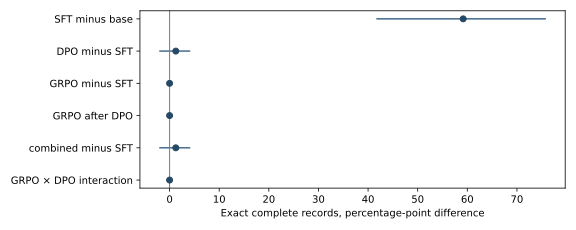

In [17]:
from IPython.display import SVG

plt.rcParams["svg.fonttype"] = "none"
figure, axis = plt.subplots(figsize=(8, 3.2))
names = list(increments) + ["GRPO × DPO interaction"]
values = list(increments.values()) + [interaction]
for position, receipt in enumerate(values):
    low, high = (100 * x for x in receipt["paired_family_bootstrap_95"])
    axis.hlines(position, low, high, color="#44698a")
    axis.scatter(100 * receipt["delta"], position, color="#254864", zorder=3)
axis.axvline(0, color="#737a81", linewidth=1)
axis.set(yticks=range(len(names)), yticklabels=names, xlabel="Exact complete records, percentage-point difference")
axis.invert_yaxis()
figure.tight_layout()
svg = OUT / "06-stage-effects.svg"
figure.savefig(svg, format="svg")
plt.close(figure)
display(SVG(filename=str(svg)))

## Sources

[Ai2 Tülu 3](https://arxiv.org/abs/2411.15124) ·
[NVIDIA Nemotron 3.5 Parse](https://huggingface.co/blog/nvidia/building-on-nemotron-35-parse-open-data-fine-tunin) ·
[Direct Preference Optimization](https://arxiv.org/abs/2305.18290) ·
[DeepSeekMath GRPO](https://arxiv.org/abs/2402.03300) ·
[Cookbook weights-only handoff](https://github.com/togethercomputer/post-training-cookbook/blob/226e03ca225d6f13434047cf0f45ab3070a29801/recipes/sft_then_grpo.py)

## Read the result

Ask what each new stage added on the same inputs and how much extra compute it used.

[Return to the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/06-test-the-training-stack).